# Background

- **Author**: RUEI-HSIANG, CHANG／張睿庠（B12303030；AI協助）
- **Created At**: 2026-11-08
- **Research Motivation and Context (why are we interested in the findings?)：**
  學生要求合理補查缺值後，把兩市G5／G6原方法擴展到全臺，沿用合併、首長、議員三池，縣市不作分群特徵，也不逐縣市另估。
  精確輸入 `data/processed/national_g5_g6_all_20261108.csv`（1574人）、`national_g5_g6_mayor_20261108.csv`（81人）、`national_g5_g6_council_20261108.csv`（1493人），均在data/processed，以下固定SHA。
  [本輪資料文件](../data/processed/national_g5_g6_20261108_documentation.ipynb)、[實際準備](../data/code/prepare_national_g5_g6_20261108.ipynb)、[原兩市方法](taipei_kaohsiung_g5_g6_yu_provisional_20261108.ipynb)。
  1583筆登記母表先沿用10/16資格快照排除9人，游智彬保留學生暫納入旗標；再只刪G5或G6缺值，不因年齡或學歷刪除。
- **Main Findings and Takeaways：**
  全國研究母表1574人，完整值合併351、首長80、議員271；缺值排除1223。三池均有22縣市，但議員199／271來自兩市，不能當全國候選人的代表性普查。
  沿用等權Hamming（對稱類別Gower）、average linkage、距離0切群，主群為P00／P01／P10／P11四組合；合併人數148／116／54／33。
  合併／議員silhouette=1來自兩個二元特徵的重複組合；首長平均0.9875，單人P11依套件定義為0，不能稱為獨立發現政治類型。K2／K3另做列序敏感度，不將一種並列合併當成唯一結論。
- **Future Direction：**
  繼續補查保存的1223人缺值佇列，尤其兩市以外議員；曹爾元親等／職務性質未明，保留未知。
  G6=0為已記錄搜尋未發現符合證據，不代表不存在親屬。少數議員縣市只保留1–3人，不解讀縣市差異或估全國家族盛行率。
  游智彬依使用者明確決定研究暫納入，官方程序與研究狀態分開；不推論選票／選舉結果影響。


In [1]:
from pathlib import Path
import hashlib, json, sys, platform
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster, cut_tree
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', 65)
VERSIONS = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                scipy=scipy.__version__, sklearn=sklearn.__version__, matplotlib=matplotlib.__version__)
print(VERSIONS)

{'python': '3.14.6', 'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.18.0', 'sklearn': '1.9.0', 'matplotlib': '3.11.0'}


In [2]:
# Locate this project portably; never select data by glob order or mtime.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'AGENTS.md').is_file() and (p/'templates').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run from within the data-science-course project.')
INPUTS = {'all': {'path': 'data/processed/national_g5_g6_all_20261108.csv', 'sha256': '961a7c075044cc66fba259fad930b0c0963935d5c8da6f754a93e8fdbd808632', 'rows': 1574}, 'mayor': {'path': 'data/processed/national_g5_g6_mayor_20261108.csv', 'sha256': '35afbe575357c6dd6d434e0f868b7c8d7d514644b22a186270d71463de2565cd', 'rows': 81}, 'council': {'path': 'data/processed/national_g5_g6_council_20261108.csv', 'sha256': '93da1f97dcc4722d84974a266e86ef144e6925dc27e67a8a16acd883d8a7bef8', 'rows': 1493}}
EXTRA_PINS={'data/processed/national_g5_g6_coverage_20261108.csv': '32b951e0b3483ae8e7fc6e73c7ab0e293de8053d6c351c6340e2a0755a4fa9c8', 'data/processed/national_g5_g6_roster_20261108.csv': 'b3e063993ee0c26d9513cc175ebfb03837dce90397f11585303d459512c7b944', 'data/processed/national_g5_g6_preparation_validation_20261108.json': '90273c17cd0c51b3d31d63436f155ae8552417583885f08ca8473e28f8481b88'}
for rel,expected in EXTRA_PINS.items():assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest()==expected
FEATURES=['G5_first_time_any_elected_office','G6_political_family']
KEY='candidate_key'
POOL_LABELS={'all':'全國合併','mayor':'全國首長','council':'全國議員'}
EN_POOL={'all':'Combined','mayor':'Mayors','council':'Councillors'}
PROFILE_LABELS={'P00':'曾參選／搜尋未發現公職親屬','P01':'曾參選／有公職親屬',
                'P10':'首次參選／搜尋未發現公職親屬','P11':'首次參選／有公職親屬'}
PROFILES=list(PROFILE_LABELS)
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
inputs={}
for pool, spec in INPUTS.items():
    path=ROOT/spec['path']
    assert path.is_file(), f'Missing exact input: {path}'
    assert sha(path)==spec['sha256'], f'Input changed: {path}'
    d=pd.read_csv(path,dtype=str,keep_default_na=False)
    assert len(d)==spec['rows'] and len(d.columns)==56
    assert {KEY,'candidate_name','county_city','office_type',*FEATURES}.issubset(d.columns)
    assert d[KEY].ne('').all() and d[KEY].is_unique
    assert d.county_city.nunique()==22
    inputs[pool]=d
assert set(inputs['mayor'].office_type)=={'直轄市長','縣（市）長'}
assert set(inputs['council'].office_type)=={'直轄市議員','縣（市）議員'}
a=set(inputs['all'][KEY]); m=set(inputs['mayor'][KEY]); c=set(inputs['council'][KEY])
assert m.isdisjoint(c) and m|c==a
for pool in ['mayor','council']:
    pd.testing.assert_frame_equal(inputs[pool].set_index(KEY).sort_index(),
        inputs['all'].set_index(KEY).loc[inputs[pool][KEY]].sort_index())
print('逐檔SHA、56欄schema、逐人鍵及三池分割通過。')
display(Markdown('**表1：合併池前10筆（資格後研究母表N=1574）；僅呈現識別與本次使用欄位。**'))
display(inputs['all'][[KEY,'candidate_name','county_city','office_type',*FEATURES]].head(10).rename(columns={KEY:'候選人鍵','candidate_name':'姓名','county_city':'縣市','office_type':'公職',FEATURES[0]:'首次參選G5',FEATURES[1]:'公職親屬G6'}))

逐檔SHA、56欄schema、逐人鍵及三池分割通過。


**表1：合併池前10筆（資格後研究母表N=1574）；僅呈現識別與本次使用欄位。**

,候選人鍵,姓名,縣市,公職,首次參選G5,公職親屬G6
0,2026-C1-001,郭璽,臺北市,直轄市長,0,0
1,2026-C1-002,沈伯洋,臺北市,直轄市長,0,1
2,2026-C1-003,蕭文乾,臺北市,直轄市長,0,0
3,2026-C1-004,唐新民,臺北市,直轄市長,0,0
4,2026-C1-005,蔣萬安,臺北市,直轄市長,0,1
5,2026-C1-006,林志成,臺北市,直轄市長,0,0
6,2026-C1-007,蘇巧慧,新北市,直轄市長,0,1
7,2026-C1-008,李四川,新北市,直轄市長,1,0
8,2026-C1-009,蘇輝湟,新北市,直轄市長,0,0
9,2026-C1-010,張善政,桃園市,直轄市長,0,0


### 變數定義與樣本規則

G5=1依楊喬茵修訂規則為首次參選任何民選公職；無可用歷史姓名／中文別名命中者本輪另標推論旗標。G5=0須支持先前參選，未當選也算。
G6=1為配偶／三親等內血親姻親曾任民選或政治任命公職；一般軍文職、單純黨職／後援會職務、僅參選而未任公職不計。G6=0是記錄搜尋未發現，不是不存在的證明。未查者與親等未明者保留缺值。
沿用既有資格審定快照；游智彬保留資格爭議研究暫納入。只因G5／G6缺值剔除，來源、縣市、資格及推論旗標只作稽核／敏感度，不入距離。

In [3]:
MISSING={'','na','n/a','nan','none','null','unknown','未知','待核','待確認'}
prepared={}; exclusions=[]; sample_rows=[]
for pool,d in inputs.items():
    x=d[FEATURES].apply(lambda s:s.str.strip())
    missing=x.apply(lambda s:s.str.lower().isin(MISSING))
    bad=(~missing)&(~x.isin(['0','1']))
    assert not bad.any().any(), f'Unexpected nonbinary values in {pool}'
    keep=~missing.any(axis=1)
    for idx in d.index[~keep]:
        exclusions.append({'pool':pool,KEY:d.at[idx,KEY],'candidate_name':d.at[idx,'candidate_name'],
            'missing_fields':';'.join(f for f in FEATURES if missing.at[idx,f]),
            'reason':'missing_G5_or_G6'})
    q=d.loc[keep].copy();q[FEATURES]=x.loc[keep]
    q=q.sort_values(KEY,kind='stable').reset_index(drop=True)
    prepared[pool]=q
    sample_rows.append({'pool':pool,'input_n':len(d),'included_n':len(q),'excluded_n':int((~keep).sum()),
                        'G5_missing_n':int(missing[FEATURES[0]].sum()),'G6_missing_n':int(missing[FEATURES[1]].sum())})
sample=pd.DataFrame(sample_rows)
exclusion_df=pd.DataFrame(exclusions,columns=['pool',KEY,'candidate_name','missing_fields','reason'])
display(Markdown('**表2：G5／G6完整觀察篩選（各池原始N見input_n）；三池非互斥。**'))
display(sample.rename(columns={'pool':'樣本池','input_n':'原始人數','included_n':'保留人數','excluded_n':'缺值排除人數','G5_missing_n':'G5缺值人數','G6_missing_n':'G6缺值人數'}))
assert sample.set_index('pool').included_n.to_dict()=={'all':351,'mayor':80,'council':271}
assert len(exclusion_df[exclusion_df.pool.eq('all')])==1223
print('仍保留年齡缺值者：',int(prepared['all'].G1_age_2026_minus_birth_year.eq('').sum()),'人；不入距離。')


**表2：G5／G6完整觀察篩選（各池原始N見input_n）；三池非互斥。**

,樣本池,原始人數,保留人數,缺值排除人數,G5缺值人數,G6缺值人數
0,all,1574,351,1223,346,1221
1,mayor,81,80,1,0,1
2,council,1493,271,1222,346,1220


仍保留年齡缺值者： 37 人；不入距離。


### 使用變數的摘要統計

G5、G6為二元類別，不因儲存為數字就當成連續變數。以下每池列出所有類別的次數與非缺值分母百分比，並另列缺值數。
縣市與公職只作樣本核對，不作地理分群或特徵。candidate_key及姓名只作識別；來源欄只是原樣保留的稽核資訊。
資格暫納入旗標只用作樣本與敏感度核對，不進距離，以下亦列其人數分布。

In [4]:
VARIABLE_LABELS={FEATURES[0]:'G5 首次參選任何民選公職',FEATURES[1]:'G6 公職親屬搜尋編碼','county_city':'縣市（不入距離）','office_type':'公職（不入距離）','eligibility_provisional_flag_20261108':'資格爭議研究暫納入旗標','G5_inferred_archive_nonmatch_20261108':'本輪G5歷史無命中推論旗標'}
VALUE_LABELS={FEATURES[0]:{'0':'曾參選','1':'首次參選'},FEATURES[1]:{'0':'搜尋未發現符合親屬','1':'有符合公職親屬'}}
summary=[]
for pool,d in prepared.items():
    for f,label in VARIABLE_LABELS.items():
        valid=d.loc[d[f].ne(''),f];counts=valid.value_counts();effective=len(valid)
        for value,n in counts.head(10).items():
            summary.append({'樣本池':POOL_LABELS[pool],'變數':label,'類別':VALUE_LABELS.get(f,{}).get(value,value),'有效N':effective,'缺值N':int(d[f].eq('').sum()),'人數':int(n),'百分比':100*n/effective})
display(Markdown('**表3：實際使用類別變數之摘要（合併351／首長80／議員271；超過10類列前10，百分比分母為該欄全部有效N）。**'))
display(pd.DataFrame(summary).round(2))


**表3：實際使用類別變數之摘要（合併351／首長80／議員271；超過10類列前10，百分比分母為該欄全部有效N）。**

,樣本池,變數,類別,有效N,缺值N,人數,百分比
0,全國合併,G5 首次參選任何民選公職,曾參選,351,0,264,75.21
1,全國合併,G5 首次參選任何民選公職,首次參選,351,0,87,24.79
2,全國合併,G6 公職親屬搜尋編碼,搜尋未發現符合親屬,351,0,202,57.55
3,全國合併,G6 公職親屬搜尋編碼,有符合公職親屬,351,0,149,42.45
4,全國合併,縣市（不入距離）,高雄市,351,0,106,30.20
5,全國合併,縣市（不入距離）,臺北市,351,0,104,29.63
6,全國合併,縣市（不入距離）,彰化縣,351,0,13,3.70
7,全國合併,縣市（不入距離）,新北市,351,0,12,3.42
8,全國合併,縣市（不入距離）,臺中市,351,0,11,3.13
9,全國合併,縣市（不入距離）,澎湖縣,351,0,10,2.85


### The actual analysis starts below

#### 距離、演算法與群數

沿用[既有提案](../report/DSSI2026-group-3.md)的對稱 Gower 類別距離及 average linkage。
本次只有兩個等權重二元欄位，距離恰等於 Hamming distance：

\[
d(i,j)=\{\mathbf{1}[G5_i\ne G5_j]+\mathbf{1}[G6_i\ne G6_j]\}/2\in\{0,0.5,1\}.
\]

G6的0也算一次有效搜尋編碼，故兩個0的相同結果會增加相似度；這是分析設定，並非親屬不存在的斷言。
先以候選人鍵排序，再將凝聚式階層樹切在距離0，保留不同已觀察組合；群數最多4，不拆開完全相同資料製造第5群。
群別以固定 P00／P01／P10／P11 表示 G5、G6 順序，方便跨池核對，沒有高低或優劣順序。

另比較 K=2到該池非空組合數（至多4）。較少群會合併不同組合；0.5距離可能並列，補做100次列順序重排。
主結果採零距離群，不把對K=4機械性最高的silhouette當成獨立選群證據。
以原提案每群約8–10人的下界8作人數診斷；全國首長完整值80人，各K是否達到每群8人依實際輸出檢查；人數下界只是診斷，不改群或拆同組合。

技術參考：[SciPy average linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)、
[scikit-learn silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)。實際套件版本見最前方輸出，未假稱與網站版本相同。

In [5]:
def canonical(labels, frame):
    # Stable local C labels for alternative K; identical IDs are not compared across K or pools.
    groups={int(label):tuple(sorted(set('P'+r[0]+r[1] for r in
             frame.loc[np.asarray(labels)==label,FEATURES].itertuples(index=False,name=None))))
            for label in np.unique(labels)}
    mapping={old:i+1 for i,old in enumerate(sorted(groups,key=lambda t:groups[t]))}
    return np.array([mapping[int(t)] for t in labels])

fits={}; assignments={}; metrics=[]; alternatives=[]; profile_rows=[]
for pool,d in prepared.items():
    X=d[FEATURES].to_numpy(dtype=int)
    distances=pdist(X,metric='hamming')
    D=squareform(distances)
    assert set(np.unique(D)).issubset({0.0,0.5,1.0})
    # Pass a condensed distance vector; do not reinterpret the square matrix as observations.
    Z=linkage(distances,method='average',optimal_ordering=False)
    primary=fcluster(Z,t=0.0,criterion='distance')
    profile='P'+d[FEATURES[0]]+d[FEATURES[1]]
    primary_k=len(np.unique(primary))
    assert primary_k==profile.nunique()
    match=pd.DataFrame({'label':primary,'profile':profile})
    assert match.groupby('label').profile.nunique().eq(1).all()
    assert match.groupby('profile').label.nunique().eq(1).all()
    sil=silhouette_samples(D,primary,metric='precomputed')
    metadata=[KEY,'candidate_name','county_city','office_type','electoral_district',*FEATURES,
              'G5_label','G6_label','G5_audit_status','G5_source','G6_evidence_tier','G6_source','G6_review_note_tk_20261108','eligibility_status_20261108','eligibility_source_20261108','research_inclusion_status_20261108','official_eligibility_note_20261108','eligibility_provisional_flag_20261108','provisional_inclusion_source_20261108','G5_inferred_archive_nonmatch_20261108','G5_completion_status_20261108','G6_completion_status_20261108']
    out=d[metadata].copy()
    out['clustering_pool']=pool
    out['cluster_profile_id']=profile
    out['cluster_profile_label']=profile.map(PROFILE_LABELS)
    out['primary_k']=primary_k
    out['primary_silhouette']=sil
    assignments[pool]=out
    fits[pool]={'X':X,'D':D,'Z':Z,'primary':primary,'profile':profile,'k':primary_k,'alternatives':{}}
    for pid,label in PROFILE_LABELS.items():
        n=int(profile.eq(pid).sum())
        profile_rows.append({'pool':pool,'profile_id':pid,'profile_label':label,'G5':int(pid[1]),'G6':int(pid[2]),
            'n':n,'pool_n':len(d),'percent':100*n/len(d),'observed':n>0})
    for k in range(2,primary_k+1):
        labels=canonical(cut_tree(Z,n_clusters=k).ravel(),d)
        fits[pool]['alternatives'][k]=labels
        counts=pd.Series(labels).value_counts().sort_index()
        patterns=['+'.join(sorted(profile[labels==label].unique())) for label in counts.index]
        metrics.append({'pool':pool,'pool_n':len(d),'requested_k':k,'actual_k':len(counts),
            'silhouette_mean':float(silhouette_score(D,labels,metric='precomputed')),
            'min_cluster_n':int(counts.min()),'max_cluster_n':int(counts.max()),
            'all_clusters_n_ge_8':bool(counts.min()>=8),'is_primary':k==primary_k,
            'cluster_sizes':'|'.join(map(str,counts.tolist())),
            'cluster_profiles':'|'.join(patterns)})
        for i,row in d.iterrows():
            alternatives.append({'pool':pool,KEY:row[KEY],'k':k,'cluster_id':f'C{labels[i]}',
                                 'cluster_profiles':patterns[int(labels[i])-1]})
profiles=pd.DataFrame(profile_rows)
diagnostics=pd.DataFrame(metrics)
alternative_assignments=pd.DataFrame(alternatives)
display(Markdown('**表4：零距離主分群人數（合併N=351、首長N=80、議員N=271）；0人組合不計入非空群數。**'))
display(profiles.pivot(index=['profile_id','profile_label'],columns='pool',values='n')[['all','mayor','council']]
        .rename(columns=POOL_LABELS))
display(Markdown('**表5：K=2–4診斷（N依pool_n；min_cluster_n為最小群人數，主結果為is_primary）。**'))
display(diagnostics.round({'silhouette_mean':4}).rename(columns={'pool':'樣本池','pool_n':'樣本人數','requested_k':'要求群數','actual_k':'實際群數','silhouette_mean':'平均silhouette','min_cluster_n':'最小群人數','max_cluster_n':'最大群人數','all_clusters_n_ge_8':'每群至少8人','is_primary':'主結果','cluster_sizes':'各群人數','cluster_profiles':'各群組合'}))

**表4：零距離主分群人數（合併N=351、首長N=80、議員N=271）；0人組合不計入非空群數。**

,pool,全國合併,全國首長,全國議員
profile_id,profile_label,,,
P00,曾參選／搜尋未發現公職親屬,148,33,115
P01,曾參選／有公職親屬,116,25,91
P10,首次參選／搜尋未發現公職親屬,54,21,33
P11,首次參選／有公職親屬,33,1,32


**表5：K=2–4診斷（N依pool_n；min_cluster_n為最小群人數，主結果為is_primary）。**

,樣本池,樣本人數,要求群數,實際群數,平均silhouette,最小群人數,最大群人數,每群至少8人,主結果,各群人數,各群組合
0,all,351,2,2,0.6716,87,264,True,False,264|87,P00+P01|P10+P11
1,all,351,3,3,0.8819,87,148,True,False,148|116|87,P00|P01|P10+P11
2,all,351,4,4,1.0000,33,148,True,True,148|116|54|33,P00|P01|P10|P11
3,mayor,80,2,2,0.7425,26,54,True,False,54|26,P00+P10|P01+P11
4,mayor,80,3,3,0.9750,21,33,True,False,33|26|21,P00|P01+P11|P10
5,mayor,80,4,4,0.9875,1,33,False,True,33|25|21|1,P00|P01|P10|P11
6,council,271,2,2,0.6675,65,206,True,False,206|65,P00+P01|P10+P11
7,council,271,3,3,0.8782,65,115,True,False,115|91|65,P00|P01|P10+P11
8,council,271,4,4,1.0000,32,115,True,True,115|91|33|32,P00|P01|P10|P11


主群逐人等於G5／G6的四個已觀察組合。非單人群內距離0、不同群距離正，所以合併／議員silhouette=1是機械結果；首長P11只有1人，其silhouette依定義0，使首長平均為0.9875。其意義接近可重現的二維交叉表，不是外部效度證明。
與兩市版使用完全相同的距離、平均連結與零距離切群。較少群會合併不同組合，需查看下方並列／列序敏感度。

In [6]:
SEED=20261108
PERMUTATIONS=100
order_rows=[]
for pool,d in prepared.items():
    fit=fits[pool];rng=np.random.default_rng(SEED)
    values={k:[] for k in fit['alternatives']}
    primary_ari=[]
    for b in range(PERMUTATIONS):
        perm=rng.permutation(len(d))
        Zp=linkage(pdist(fit['X'][perm],metric='hamming'),method='average')
        lp=fcluster(Zp,t=0,criterion='distance')
        back=np.empty(len(d),dtype=int);back[perm]=lp
        primary_ari.append(adjusted_rand_score(fit['primary'],back))
        for k,base in fit['alternatives'].items():
            lp=cut_tree(Zp,n_clusters=k).ravel()
            back=np.empty(len(d),dtype=int);back[perm]=lp
            values[k].append(adjusted_rand_score(base,back))
    assert np.allclose(primary_ari,1)
    for k,scores in values.items():
        order_rows.append({'pool':pool,'k':k,'permutations':PERMUTATIONS,'seed':SEED,
            'ARI_min':min(scores),'ARI_mean':float(np.mean(scores)),
            'same_partition_fraction':float(np.mean(np.isclose(scores,1))),
            'primary_profile_cut':k==fit['k']})
order_check=pd.DataFrame(order_rows)
display(Markdown('**表6：100次列順序重排（各池N不變）；ARI=1表示相同分割，僅檢查距離並列的實作敏感度。**'))
display(order_check.round(4).rename(columns={'pool':'樣本池','k':'群數','permutations':'重排次數','seed':'亂數種子','ARI_min':'最小ARI','ARI_mean':'平均ARI','same_partition_fraction':'相同分割比例','primary_profile_cut':'主結果'}))

**表6：100次列順序重排（各池N不變）；ARI=1表示相同分割，僅檢查距離並列的實作敏感度。**

,樣本池,群數,重排次數,亂數種子,最小ARI,平均ARI,相同分割比例,主結果
0,all,2,100,20261108,-0.0070,0.5771,0.58,False
1,all,3,100,20261108,0.4177,0.8942,0.57,False
2,all,4,100,20261108,1.0000,1.0000,1.00,True
3,mayor,2,100,20261108,-0.0116,0.4639,0.47,False
4,mayor,3,100,20261108,0.9674,0.9827,0.47,False
5,mayor,4,100,20261108,1.0000,1.0000,1.00,True
6,council,2,100,20261108,0.0022,0.7007,0.70,False
7,council,3,100,20261108,0.4080,0.8881,0.64,False
8,council,4,100,20261108,1.0000,1.0000,1.00,True


#### Bootstrap：小群是否會在重抽中消失

依提案補做500次候選人等機率有放回重抽，各次仍使用平均連結、距離0切群；固定seed=20261108。
重複抽中的同一候選人以集合計算Jaccard，不將複本當成新人物。
每個原群與重抽群比對最大Jaccard，分別報告：
(1) 原群完整候選人集合的平均Jaccard（未被抽中的原成員仍在分母，因此受抽樣涵蓋率影響）；
(2) 只比較當次抽到的共同支持集合、且原群有被抽到時的平均Jaccard；
(3) 原群完全沒被抽到的比例。
在本題共同支持分群一致是相同兩欄組合的必然結果，不能視為對來源編碼正確性、外部效度或潛在類型的認證。

In [7]:
BOOTSTRAPS=500
bootstrap_rows=[]
for pool,d in prepared.items():
    fit=fits[pool];rng=np.random.default_rng(SEED)
    groups={pid:set(np.flatnonzero(fit['profile'].to_numpy()==pid))
            for pid in PROFILES if (fit['profile']==pid).any()}
    records={pid:{'full':[],'common':[],'absent':0} for pid in groups}
    for b in range(BOOTSTRAPS):
        draw=rng.integers(0,len(d),size=len(d))
        boot=fit['X'][draw]
        Zb=linkage(pdist(boot,metric='hamming'),method='average')
        lab=fcluster(Zb,t=0,criterion='distance')
        boot_groups=[set(draw[lab==label].tolist()) for label in np.unique(lab)]
        support=set(draw.tolist())
        for pid,original in groups.items():
            common=original&support
            records[pid]['full'].append(max(len(original&g)/len(original|g) for g in boot_groups))
            if not common:
                records[pid]['absent']+=1
            else:
                records[pid]['common'].append(max(len(common&g)/len(common|g) for g in boot_groups))
    for pid,r in records.items():
        bootstrap_rows.append({'pool':pool,'profile_id':pid,'original_n':len(groups[pid]),
            'pool_n':len(d),'B':BOOTSTRAPS,'seed':SEED,
            'jaccard_full_universe_mean':float(np.mean(r['full'])),
            'jaccard_common_support_mean_when_present':float(np.mean(r['common'])),
            'absent_n':r['absent'],'absent_fraction':r['absent']/BOOTSTRAPS})
bootstrap=pd.DataFrame(bootstrap_rows)
display(Markdown('**表7：主分群500次bootstrap（各池N見pool_n）；完整集合Jaccard受重抽涵蓋率影響，非信賴區間。**'))
display(bootstrap.round(4).rename(columns={'pool':'樣本池','profile_id':'組合','original_n':'原群人數','pool_n':'樣本人數','B':'重抽次數','seed':'亂數種子','jaccard_full_universe_mean':'完整原群平均Jaccard','jaccard_common_support_mean_when_present':'抽到成員條件下平均Jaccard','absent_n':'整群未抽到次數','absent_fraction':'整群未抽到比例'}))

**表7：主分群500次bootstrap（各池N見pool_n）；完整集合Jaccard受重抽涵蓋率影響，非信賴區間。**

,樣本池,組合,原群人數,樣本人數,重抽次數,亂數種子,完整原群平均Jaccard,抽到成員條件下平均Jaccard,整群未抽到次數,整群未抽到比例
0,all,P00,148,351,500,20261108,0.6335,1.0,0,0.000
1,all,P01,116,351,500,20261108,0.6302,1.0,0,0.000
2,all,P10,54,351,500,20261108,0.6307,1.0,0,0.000
3,all,P11,33,351,500,20261108,0.6311,1.0,0,0.000
4,mayor,P00,33,80,500,20261108,0.6305,1.0,0,0.000
5,mayor,P01,25,80,500,20261108,0.6315,1.0,0,0.000
6,mayor,P10,21,80,500,20261108,0.6383,1.0,0,0.000
7,mayor,P11,1,80,500,20261108,0.6420,1.0,179,0.358
8,council,P00,115,271,500,20261108,0.6323,1.0,0,0.000
9,council,P01,91,271,500,20261108,0.6351,1.0,0,0.000


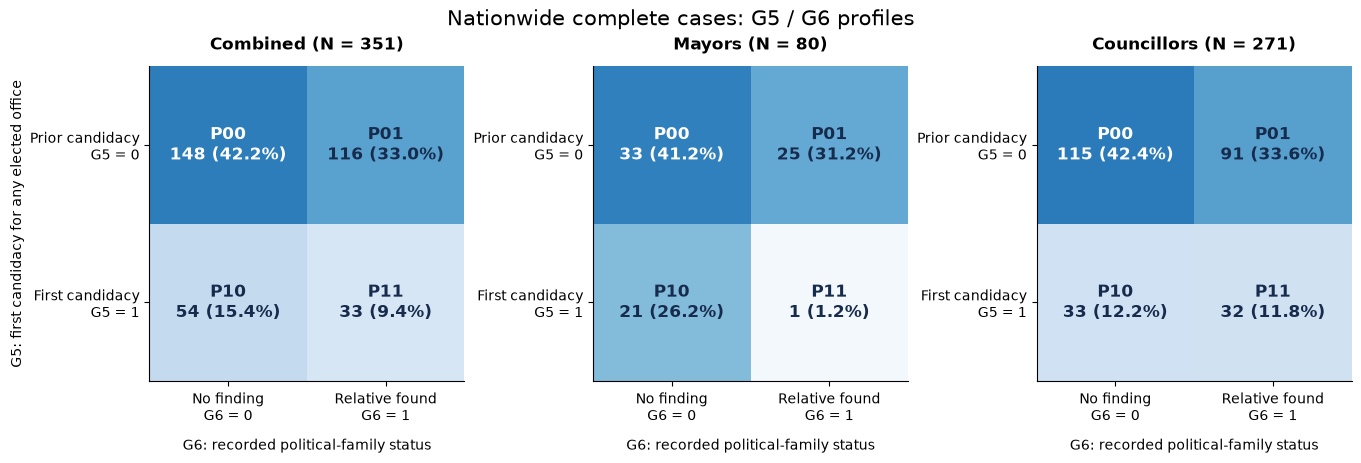

In [8]:
ASSET=ROOT/'finding/national_g5_g6_clustering_20261108_assets'
ASSET.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,3,figsize=(13.5,4.5),constrained_layout=True)
for ax,pool in zip(axes,INPUTS):
    counts=profiles[profiles.pool==pool].set_index('profile_id').n
    ns=np.array([[counts['P00'],counts['P01']],[counts['P10'],counts['P11']]])
    perc=100*ns/len(prepared[pool])
    ax.imshow(perc,vmin=0,vmax=60,cmap='Blues',aspect='equal')
    for i in range(2):
        for j in range(2):
            pid=f'P{i}{j}'
            ax.text(j,i,f'{pid}\n{ns[i,j]} ({perc[i,j]:.1f}%)',ha='center',va='center',
                    color='white' if perc[i,j]>40 else '#172b4d',fontsize=12,fontweight='bold')
    ax.set_xticks([0,1],['No finding\nG6 = 0','Relative found\nG6 = 1'])
    ax.set_yticks([0,1],['Prior candidacy\nG5 = 0','First candidacy\nG5 = 1'])
    ax.set_xlabel('G6: recorded political-family status',labelpad=10)
    ax.set_ylabel('G5: first candidacy for any elected office' if pool=='all' else '')
    ax.set_title(f'{EN_POOL[pool]} (N = {len(prepared[pool])})',fontweight='bold',pad=12)
fig.suptitle('Nationwide complete cases: G5 / G6 profiles',fontsize=15)
fig.savefig(ASSET/'profile_counts.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

圖1呈現全臺完整值研究樣本的四組合人數與池內比例。No finding為已記錄搜尋未發現符合公職親屬，不能稱「確定沒有政治家庭」。
三池樣本不同且有重複；合併池就是首長與議員的聯集，不能把三池人數相加。屬觀察分布，不加不適用的母體平均值信賴區間。

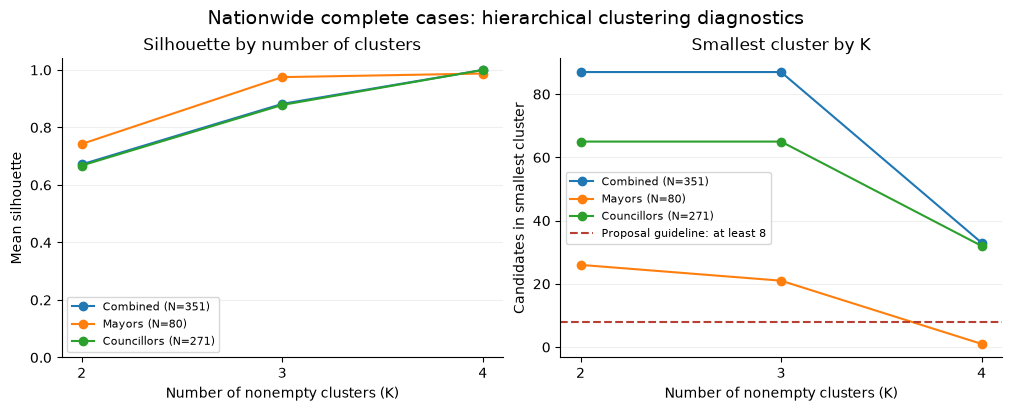

In [9]:
fig,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
for pool,g in diagnostics.groupby('pool',sort=False):
    label=f'{EN_POOL[pool]} (N={len(prepared[pool])})'
    axes[0].plot(g.requested_k,g.silhouette_mean,marker='o',label=label)
    axes[1].plot(g.requested_k,g.min_cluster_n,marker='o',label=label)
axes[0].set(title='Silhouette by number of clusters',xlabel='Number of nonempty clusters (K)',ylabel='Mean silhouette',ylim=(0,1.04))
axes[1].set(title='Smallest cluster by K',xlabel='Number of nonempty clusters (K)',ylabel='Candidates in smallest cluster')
axes[1].axhline(8,color='#b74032',linestyle='--',label='Proposal guideline: at least 8')
for ax in axes:
    ax.set_xticks([2,3,4]);ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2)
fig.suptitle('Nationwide complete cases: hierarchical clustering diagnostics',fontsize=14)
fig.savefig(ASSET/'k_diagnostics.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

圖2比較K的分離度及最小群人數。零距離主群保留全部二元組合；silhouette=1不能單獨替K=4提供實質選群證據。國家範圍擴大後首長仍須檢查小群，不把原兩市N=11的限制直接照抄。

### 全國覆蓋與證據敏感度

各縣市完整值保留率與母表分母並列，縣市只作覆蓋描述。分群本身只有G5、G6。
另依序排除本輪僅歷史檔無命中推論的G5個案、資格爭議游智彬，以及同時排除兩者，重新以同法分群；共同人員主群ARI與百分比差只衡量編碼／樣本敏感度，不衡量真實選舉效果。

**表8：全國研究母表保留率（66列＝3池×22縣市；缺值排除欄有重疊，不相加）。**

,池,縣市,研究母表N,完整值N,缺值排除N,G5缺值N,G6缺值N,保留百分比,本輪G5推論人數
0,all,南投縣,63,5,58,21,58,7.94,12
1,all,嘉義市,42,7,35,9,35,16.67,6
2,all,嘉義縣,54,5,49,17,48,9.26,4
3,all,基隆市,62,7,55,10,55,11.29,27
4,all,宜蘭縣,64,6,58,16,58,9.38,14
...,...,...,...,...,...,...,...,...,...
61,council,苗栗縣,56,2,54,19,54,3.57,9
62,council,連江縣,14,2,12,4,12,14.29,0
63,council,金門縣,34,2,32,9,31,5.88,13
64,council,雲林縣,72,1,71,24,71,1.39,20


**表9：編碼／資格敏感度，各情境N見scenario_n；共同主群ARI=1是固定二元組合的必然性。**

,pool,scenario,main_n,scenario_n,excluded_n,observed_k,primary_common_ARI,maximum_absolute_profile_change_pp
0,all,main,351,351,0,4,1.0,0.0000
1,all,exclude_current_archive_inference,351,343,8,4,1.0,2.1131
2,all,exclude_provisional_Yu,351,350,1,4,1.0,0.1652
3,all,exclude_both,351,342,9,4,1.0,2.0918
4,mayor,main,80,80,0,4,1.0,0.0000
5,mayor,exclude_current_archive_inference,80,80,0,4,1.0,0.0000
6,mayor,exclude_provisional_Yu,80,80,0,4,1.0,0.0000
7,mayor,exclude_both,80,80,0,4,1.0,0.0000
8,council,main,271,271,0,4,1.0,0.0000
9,council,exclude_current_archive_inference,271,263,8,4,1.0,2.6826


**表10：兩市與其他20縣市的樣本構成／保留率。這是資料覆蓋，不是兩個額外分群池。**

,pool,scope,research_roster_n,complete_case_n,share_of_analysis_percent,retention_percent
0,all,Taipei_Kaohsiung,210,210,59.83,100.00
1,all,Other_20_counties,1364,141,40.17,10.34
2,mayor,Taipei_Kaohsiung,11,11,13.75,100.00
3,mayor,Other_20_counties,70,69,86.25,98.57
4,council,Taipei_Kaohsiung,199,199,73.43,100.00
5,council,Other_20_counties,1294,72,26.57,5.56


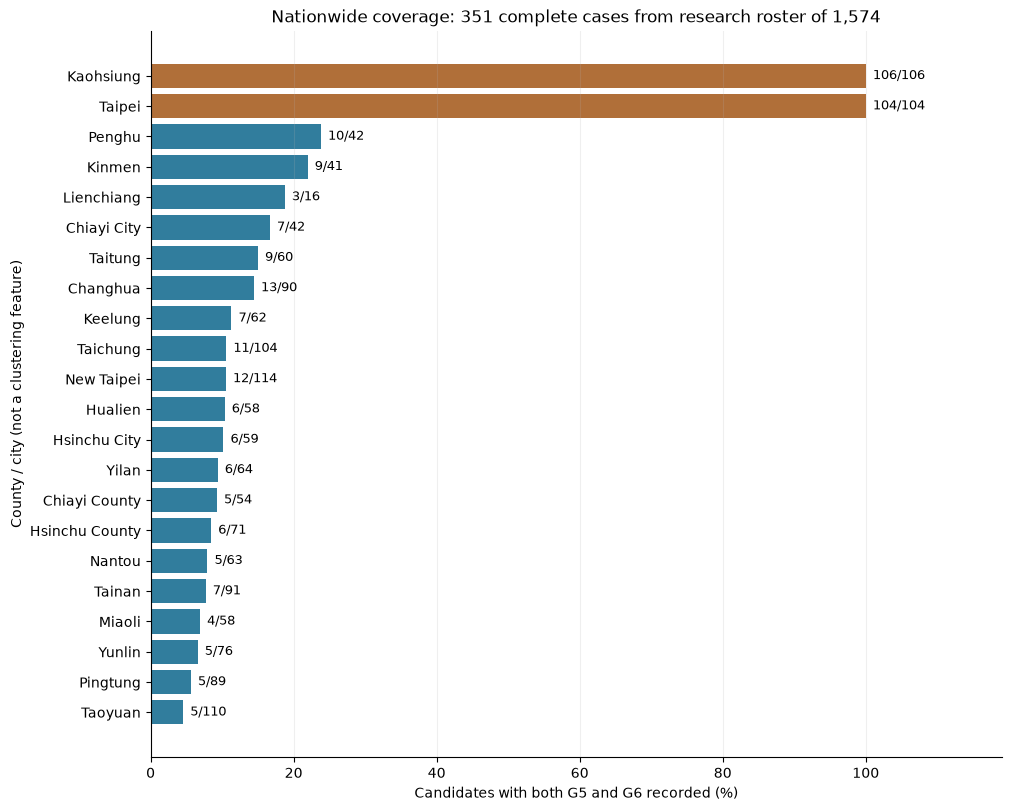

In [10]:
coverage=pd.read_csv(ROOT/'data/processed/national_g5_g6_coverage_20261108.csv')
assert len(coverage)==66 and coverage.complete_case_n.gt(0).all()
for pool in INPUTS:
    assert coverage[coverage.pool.eq(pool)].complete_case_n.sum()==len(prepared[pool])
display(Markdown('**表8：全國研究母表保留率（66列＝3池×22縣市；缺值排除欄有重疊，不相加）。**'))
display(coverage.rename(columns={'pool':'池','county_city':'縣市','research_roster_n':'研究母表N','complete_case_n':'完整值N','excluded_missing_n':'缺值排除N','missing_G5_n':'G5缺值N','missing_G6_n':'G6缺值N','retention_percent':'保留百分比','archive_inferred_G5_n':'本輪G5推論人數'}).round(2))
sensitivity_rows=[];profile_sensitivity_rows=[]
for pool,d in prepared.items():
    for scenario in ['main','exclude_current_archive_inference','exclude_provisional_Yu','exclude_both']:
        keep=pd.Series(True,index=d.index)
        if scenario in ['exclude_current_archive_inference','exclude_both']:keep &= d.G5_inferred_archive_nonmatch_20261108.ne('1')
        if scenario in ['exclude_provisional_Yu','exclude_both']:keep &= d.eligibility_provisional_flag_20261108.ne('1')
        q=d.loc[keep].reset_index(drop=True);D=squareform(pdist(q[FEATURES].to_numpy(int),metric='hamming'));Z=linkage(pdist(q[FEATURES].to_numpy(int),metric='hamming'),method='average')
        labels=fcluster(Z,t=0,criterion='distance');pid='P'+q[FEATURES[0]]+q[FEATURES[1]]
        assert adjusted_rand_score(labels,pid)==1
        mainpid=assignments[pool].set_index(KEY).loc[q[KEY],'cluster_profile_id'].to_numpy()
        ari=float(adjusted_rand_score(mainpid,labels));assert ari==1
        delta=[]
        for p in PROFILES:
            nn=int(pid.eq(p).sum());pct=100*nn/len(q);mainpct=float(profiles[(profiles.pool==pool)&profiles.profile_id.eq(p)].percent.iloc[0])
            delta.append(pct-mainpct);profile_sensitivity_rows.append({'pool':pool,'scenario':scenario,'profile_id':p,'n':nn,'pool_n':len(q),'percent':pct,'main_percent':mainpct,'difference_pp':pct-mainpct})
        sensitivity_rows.append({'pool':pool,'scenario':scenario,'main_n':len(d),'scenario_n':len(q),'excluded_n':len(d)-len(q),'observed_k':len(np.unique(labels)),'primary_common_ARI':ari,'maximum_absolute_profile_change_pp':max(map(abs,delta))})
sensitivity=pd.DataFrame(sensitivity_rows);profile_sensitivity=pd.DataFrame(profile_sensitivity_rows)
display(Markdown('**表9：編碼／資格敏感度，各情境N見scenario_n；共同主群ARI=1是固定二元組合的必然性。**'))
display(sensitivity.round(4))
# Observed composition, never an estimate of political-family prevalence.
composition=[]
for pool,d in prepared.items():
    for scope in ['Taipei_Kaohsiung','Other_20_counties']:
        mask=d.county_city.isin(['臺北市','高雄市']);mask=mask if scope=='Taipei_Kaohsiung' else ~mask
        denom=inputs[pool].county_city.isin(['臺北市','高雄市']);denom=denom if scope=='Taipei_Kaohsiung' else ~denom
        composition.append({'pool':pool,'scope':scope,'research_roster_n':int(denom.sum()),'complete_case_n':int(mask.sum()),'share_of_analysis_percent':100*mask.mean(),'retention_percent':100*mask.sum()/denom.sum()})
composition=pd.DataFrame(composition)
display(Markdown('**表10：兩市與其他20縣市的樣本構成／保留率。這是資料覆蓋，不是兩個額外分群池。**'))
display(composition.round(2))
# Figure 3: show full 22 county coverage without unreadable CJK labels in local fonts.
county_en={'臺北市':'Taipei','新北市':'New Taipei','桃園市':'Taoyuan','臺中市':'Taichung','臺南市':'Tainan','高雄市':'Kaohsiung','基隆市':'Keelung','新竹市':'Hsinchu City','新竹縣':'Hsinchu County','苗栗縣':'Miaoli','彰化縣':'Changhua','南投縣':'Nantou','雲林縣':'Yunlin','嘉義市':'Chiayi City','嘉義縣':'Chiayi County','屏東縣':'Pingtung','宜蘭縣':'Yilan','花蓮縣':'Hualien','臺東縣':'Taitung','澎湖縣':'Penghu','金門縣':'Kinmen','連江縣':'Lienchiang'}
cov=coverage[coverage.pool.eq('all')].sort_values('retention_percent')
fig,ax=plt.subplots(figsize=(10,8),constrained_layout=True)
y=np.arange(len(cov));ax.barh(y,cov.retention_percent,color=['#b06f39' if c in ['臺北市','高雄市'] else '#317d9d' for c in cov.county_city])
ax.set_yticks(y,[county_en[c] for c in cov.county_city]);ax.set_xlim(0,119)
for i,row in enumerate(cov.itertuples()):ax.text(row.retention_percent+1,i,f'{row.complete_case_n}/{row.research_roster_n}',va='center',fontsize=9)
ax.set(title='Nationwide coverage: 351 complete cases from research roster of 1,574',xlabel='Candidates with both G5 and G6 recorded (%)',ylabel='County / city (not a clustering feature)')
ax.grid(axis='x',alpha=.2);fig.savefig(ASSET/'county_coverage.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)


In [11]:
# Save analysis outputs, then reopen the exact serialized files and verify every cell.
OUT=ROOT/'data/processed'
STEM='national_g5_g6_'
SUFFIX='_20261108.csv'
outputs={f'{STEM}{pool}_assignments{SUFFIX}':d for pool,d in assignments.items()}
outputs.update({
 f'{STEM}profiles{SUFFIX}':profiles,
 f'{STEM}k_diagnostics{SUFFIX}':diagnostics,
 f'{STEM}alternative_assignments{SUFFIX}':alternative_assignments,
 f'{STEM}exclusions{SUFFIX}':exclusion_df,
 f'{STEM}order_sensitivity{SUFFIX}':order_check,
 f'{STEM}bootstrap{SUFFIX}':bootstrap,
 f'{STEM}evidence_sensitivity{SUFFIX}':sensitivity,
 f'{STEM}profile_sensitivity{SUFFIX}':profile_sensitivity,
 f'{STEM}composition{SUFFIX}':composition,
})
manifest=[]
for filename,frame in outputs.items():
    path=OUT/filename
    frame.to_csv(path,index=False,encoding='utf-8-sig',float_format='%.12g')
    actual=pd.read_csv(path,dtype=str,keep_default_na=False)
    # Match serialized values, including the agreed 12-significant-digit float representation.
    from io import StringIO
    expected=pd.read_csv(StringIO(frame.to_csv(index=False,float_format='%.12g')),dtype=str,keep_default_na=False)
    pd.testing.assert_frame_equal(actual,expected)
    manifest.append({'path':str(path.relative_to(ROOT)),'rows':len(actual),'columns':list(actual.columns),
                     'sha256':sha(path),'verification':'saved CSV reopened; exact schema, row order and serialized cell equality'})
# Task-level checks on saved candidate assignments.
saved={pool:pd.read_csv(OUT/f'{STEM}{pool}_assignments{SUFFIX}',dtype=str,keep_default_na=False) for pool in INPUTS}
for pool,d in saved.items():
    assert d[KEY].is_unique and set(d[KEY])==set(prepared[pool][KEY])
    assert d[FEATURES].isin(['0','1']).all().all()
    assert (d.cluster_profile_id=='P'+d[FEATURES[0]]+d[FEATURES[1]]).all()
    assert d.clustering_pool.eq(pool).all()
    assert d.primary_silhouette.astype(float).between(-1,1).all()
assert set(saved['mayor'][KEY]).isdisjoint(saved['council'][KEY])
assert set(saved['mayor'][KEY])|set(saved['council'][KEY])==set(saved['all'][KEY])
for pool in ['mayor','council']:
    # Profile IDs, not arbitrary local alternative labels, agree across pools.
    lookup=saved['all'].set_index(KEY).cluster_profile_id
    assert saved[pool].cluster_profile_id.eq(saved[pool][KEY].map(lookup)).all()
for pool,spec in INPUTS.items(): assert sha(ROOT/spec['path'])==spec['sha256']
for rel,expected in EXTRA_PINS.items():assert sha(ROOT/rel)==expected
manifest_path=OUT/'national_g5_g6_output_manifest_20261108.json'
manifest_path.write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
assert json.loads(manifest_path.read_text())==manifest
validation={
 'executed_date':'2026-11-08','analysis_features':FEATURES,'distance':'equal-weight symmetric categorical Gower = Hamming','linkage':'average','primary_cut_distance':0,'primary_k':{p:f['k'] for p,f in fits.items()},'input_bindings':INPUTS,'extra_bindings':EXTRA_PINS,'sample':sample.to_dict('records'),'saved_csv_count':len(outputs),'saved_csv_readback':True,'unique_candidate_keys':True,'three_pool_partition':True,'cross_pool_profile_ids_agree':True,'primary_order_invariance_100_permutations':True,'bootstrap_replicates':BOOTSTRAPS,'seed':SEED,'versions':VERSIONS,'mayor_minimum_size_guideline_passed':bool(diagnostics[(diagnostics.pool=='mayor')&diagnostics.is_primary].all_clusters_n_ge_8.iloc[0]),'national_scope_counties_each_pool':22,'research_roster_n':1574,'complete_case_n':351,'excluded_missing_n':1223,'G6_zero_means':'recorded targeted search found no qualifying relative; not proof of absence','G5_archive_inference_in_analysis_n':int(prepared['all'].G5_inferred_archive_nonmatch_20261108.eq('1').sum()),'Yu_provisionally_included':True,'official_eligibility_approval_claimed':False,'all_nationwide_G6_searched':False,'election_results_impact_assessed':False,'limitations':['Only two binary features: observed profiles; replicated groups mechanically have silhouette 1, singleton 0.','Nationwide roster scope does not imply complete coverage or representativeness.','Councillor analysis is dominated by Taipei/Kaohsiung; selection on available G5/G6 evidence.','G6 negative searches have unequal visibility and do not prove family absence.','Archive nonmatches are inferred first candidacy, not complete lifetime evidence.','Yu is included by explicit research decision, not certified eligible.']}

validation_path=OUT/'national_g5_g6_validation_20261108.json'
validation_path.write_text(json.dumps(validation,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
assert json.loads(validation_path.read_text())==validation
print('PASS: 12 saved CSVs reopened; schema/cells/keys/partition/profiles and unchanged input hashes verified.')
display(pd.DataFrame(manifest)[['path','rows','sha256']].rename(columns={'path':'保存路徑','rows':'列數','sha256':'SHA-256'}))

PASS: 12 saved CSVs reopened; schema/cells/keys/partition/profiles and unchanged input hashes verified.


,保存路徑,列數,SHA-256
0,data/processed/national_g5_g6_all_assignments_20261108.csv,351,f594575f0cb1800ab5209117d3496c38606f7cf77c304c785e9755776419e9c2
1,data/processed/national_g5_g6_mayor_assignments_20261108.csv,80,c2cfbd2be50bab810d37ef91e6b8a27f50c03f1c1299461657f1183084192f16
2,data/processed/national_g5_g6_council_assignments_20261108.csv,271,30665af4fa12739f85629d235a798e7ce3cde79d490e157584455b9e71c9ddf7
3,data/processed/national_g5_g6_profiles_20261108.csv,12,1372649e270bf303afc475f81d5369e927c9719bcfeb16353b8870e6b8705932
4,data/processed/national_g5_g6_k_diagnostics_20261108.csv,9,599e504a2e641973686a72ad760adf784a065f8fbd4c9c1ec3fa4cc3325bb53c
5,data/processed/national_g5_g6_alternative_assignments_2026110...,2106,602dace871e0bad59e22e1b0387cc5c3b7e769572c8708a895be346a2b7be368
6,data/processed/national_g5_g6_exclusions_20261108.csv,2446,154166490f0bf5f11faee9430324909f0880ad47e94f56a6730d2b911f3f983c
7,data/processed/national_g5_g6_order_sensitivity_20261108.csv,9,8e2b35858fad0ddc29db4186a76e9c877b0731ba0d548612a6d1c30799469a5e
8,data/processed/national_g5_g6_bootstrap_20261108.csv,12,995865fd02051dc2ca4ad7a4f6bfd3b77f480076587f70e2d5728bb97bb67adb
9,data/processed/national_g5_g6_evidence_sensitivity_20261108.csv,12,80d990390088139d6b8d1f338d953482f91e9940d2f57891d4c3c934c0bdada4


### 結果使用與限制

全臺範圍研究母表1574筆，但只351筆G5／G6完整進入分群。首長80／81完整、議員271／1493完整，議員中199人為臺北／高雄；不能稱全國候選人已全部補齊，不能從這個選樣估全國政治家族比例。
完整值主群是兩二元特徵的四格，100次列序不變與bootstrap共同支撐集合Jaccard=1均有機械性；請同看K2／K3的並列敏感度及完整集合的抽樣涵蓋率。
缺值清單、9位資格排除及游智彬暫納入狀態均可按鍵追蹤。保留原兩市檔作方法／歷史比較，不覆寫其成果。
[結果報告](../report/national_g5_g6_clustering_20261108.md)、[資料文件](../data/processed/national_g5_g6_20261108_documentation.ipynb)。本地未提交，沒有stage、commit或push。
